# Passo a passo · Avaliação de modelos com scikit-learn
**Fundamentos de Machine Learning · Aula 5 · Prática guiada**

Nas aulas 2 e 3 treinamos uma regressão linear e uma regressão logística. Agora a pergunta é outra: **o modelo é bom?** Para responder, vamos medir o desempenho dos dois modelos em dados que eles não viram, com as métricas dos slides da aula.

Usamos as mesmas bases das aulas anteriores:

| Parte | Problema | Base | Alvo |
|---|---|---|---|
| A | Classificação binária | *Pima Indians Diabetes* (aula 3) | `Outcome`: 1 = diabetes, 0 = sem diabetes |
| B | Regressão | *Advertising* (aula 2) | `Sales`: vendas em mil unidades |
| C | As duas | as duas | validação cruzada |

**Roteiro**

1. Preparar a base de diabetes e treinar o classificador
2. Treino × teste e a linha de base
3. Matriz de confusão
4. Acurácia, precisão, revocação, especificidade e F1 (na mão e com o scikit-learn)
5. O limiar de decisão
6. Curva ROC e AUC
7. Curva precisão-revocação
8. Escolher o limiar sem olhar o teste
9. Regressão: resíduos, MAE, MSE, RMSE e R²
10. Gráfico de resíduos
11. Validação cruzada e `Pipeline`

> Todos os números citados no texto foram obtidos executando este notebook. Se você mudar `random_state` ou a lista de features, os valores mudam.

## Etapa 0 · Importar as bibliotecas

In [28]:
import numpy as np                                     # cálculos numéricos
import pandas as pd                                    # leitura e manipulação de tabelas
import matplotlib.pyplot as plt                        # gráficos

from sklearn.model_selection import train_test_split, cross_val_score, cross_validate
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
    recall_score, f1_score, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score)

---
# Parte A · Classificação binária: diabetes

## Etapa 1 · Carregar e limpar a base

Repetimos a limpeza da aula 3, sem novidades:
- `Glucose`, `BloodPressure` e `BMI` usam **0** para indicar medida não registrada. Trocamos por `NaN` e removemos essas linhas.
- `SkinThickness` e `Insulin` têm zeros em boa parte das linhas e ficam de fora.

In [2]:
df = pd.read_csv('../../data/diabetes.csv')

df_limpo = df.drop(columns=['SkinThickness', 'Insulin']).copy()
cols = ['Glucose', 'BloodPressure', 'BMI']
df_limpo[cols] = df_limpo[cols].replace(0, np.nan)
df_limpo = df_limpo.dropna()

print(f'{len(df)} linhas originais; {len(df_limpo)} após a limpeza')
df_limpo['Outcome'].value_counts()

768 linhas originais; 724 após a limpeza


Outcome
0    475
1    249
Name: count, dtype: int64

Há cerca de **2 pacientes sem diabetes para cada 1 com diabetes**. Essa proporção, que já apareceu na aula 3, vai ser importante para interpretar as métricas.

## Etapa 2 · Separar treino e teste e treinar o modelo

Usamos as 6 features da última etapa da aula 3. A separação é a mesma: 20% para teste, `random_state=42` e `stratify=y`.

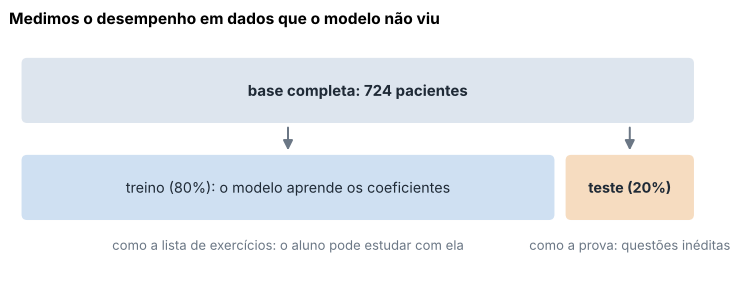

*O teste funciona como uma prova com questões inéditas. Se a prova repetisse a lista de exercícios, ela mediria memória, e não aprendizado.*

In [3]:
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df_limpo[features]
y = df_limpo['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print(f'Proporção de diabetes: treino {y_train.mean():.3f} | teste {y_test.mean():.3f}')

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)

Treino: (579, 6) | Teste: (145, 6)
Proporção de diabetes: treino 0.344 | teste 0.345


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### Treino × teste

O método `score` de um classificador devolve a **acurácia** (proporção de acertos). Vamos calculá-la nos dois conjuntos.

In [4]:
print(f'acurácia no treino: {modelo.score(X_train, y_train):.3f}')
print(f'acurácia no teste : {modelo.score(X_test, y_test):.3f}')

acurácia no treino: 0.794
acurácia no teste : 0.703


O modelo acerta mais no treino do que no teste. O treino foi usado para ajustar os coeficientes, por isso o desempenho nele é **otimista**. A partir daqui, **todas as métricas são calculadas no conjunto de teste**.

### A linha de base (baseline)

Uma acurácia de 70% é boa? Depende da referência. O `DummyClassifier` com `strategy='most_frequent'` responde sempre a classe mais comum do treino (sem diabetes) e ignora as features.

In [5]:
base = DummyClassifier(strategy='most_frequent')
base.fit(X_train, y_train)

print(f'acurácia da linha de base: {base.score(X_test, y_test):.3f}')
print(f'acurácia do modelo       : {modelo.score(X_test, y_test):.3f}')

acurácia da linha de base: 0.655
acurácia do modelo       : 0.703


**Para discutir:** a linha de base acerta 65,5% sem aprender nada, só porque 65,5% das pacientes de teste não têm diabetes. O ganho real do modelo é de cerca de 5 pontos percentuais. Qual seria a acurácia da linha de base numa doença que atinge 1% da população?

## Etapa 3 · A matriz de confusão

Em classificação binária existem **quatro** resultados possíveis para cada paciente: o modelo pode acertar de dois jeitos e errar de dois jeitos. A matriz de confusão conta quantas pacientes caíram em cada caso.

"Positivo" é a classe 1, a que queremos detectar (aqui, ter diabetes). "Positivo" não quer dizer "bom".

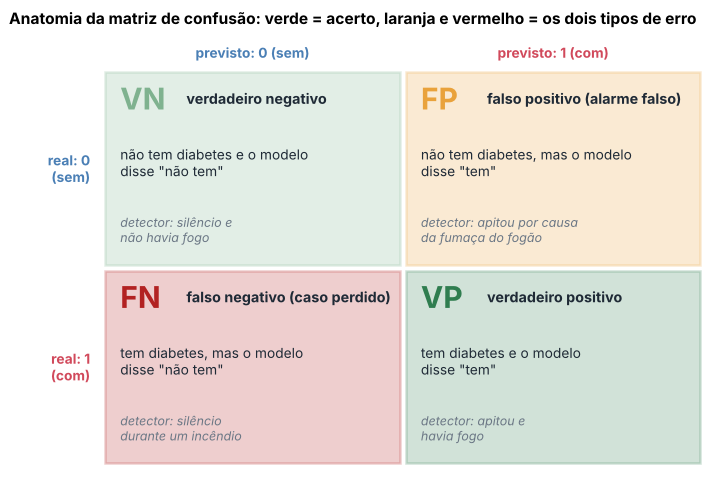

*Um detector de fumaça é um classificador binário: "há fogo" ou "não há fogo". O FP incomoda; o FN pode ser grave.*

`predict` aplica o limiar 0,5 às probabilidades. Comparamos as classes previstas com as reais:

In [6]:
y_pred = modelo.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
cm

array([[75, 20],
       [23, 27]])

No scikit-learn, **linhas são a classe real e colunas a classe prevista**, nesta ordem:

|  | previsto 0 | previsto 1 |
|---|---|---|
| **real 0** | VN (verdadeiro negativo) | FP (falso positivo, alarme falso) |
| **real 1** | FN (falso negativo, diabetes não detectada) | VP (verdadeiro positivo) |

O `ravel()` "achata" a matriz na ordem VN, FP, FN, VP:

In [7]:
vn, fp, fn, vp = cm.ravel()
print(f'VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}')
print(f'total = {vn + fp + fn + vp} pacientes de teste')

VN = 75 | FP = 20 | FN = 23 | VP = 27
total = 145 pacientes de teste


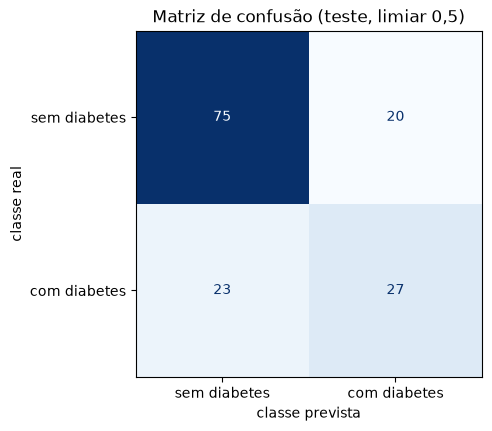

In [8]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['sem diabetes', 'com diabetes']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_xlabel('classe prevista'); ax.set_ylabel('classe real')
ax.set_title('Matriz de confusão (teste, limiar 0,5)')
plt.show()

**Leitura:** das 50 pacientes com diabetes, o modelo detectou 27 e deixou passar 23. Das 95 sem diabetes, emitiu 20 alarmes falsos.

## Etapa 4 · As métricas, na mão e com o scikit-learn

Todas saem das quatro contagens:

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| acurácia | (VP + VN) / (VP + VN + FN + FP) | qual fração das previsões está certa? |
| precisão | VP / (VP + FP) | dos alertas emitidos, quantos estavam certos? |
| revocação (*recall*, sensibilidade) | VP / (VP + FN) | dos casos reais, quantos foram detectados? |
| especificidade | VN / (VN + FP) | das pacientes sem diabetes, quantas foram liberadas corretamente? |
| F1 | 2·P·R / (P + R) | média harmônica de precisão e revocação |

A diferença mais importante é entre **precisão** e **revocação**. As duas têm VP no numerador, mas olham para grupos diferentes de pacientes:

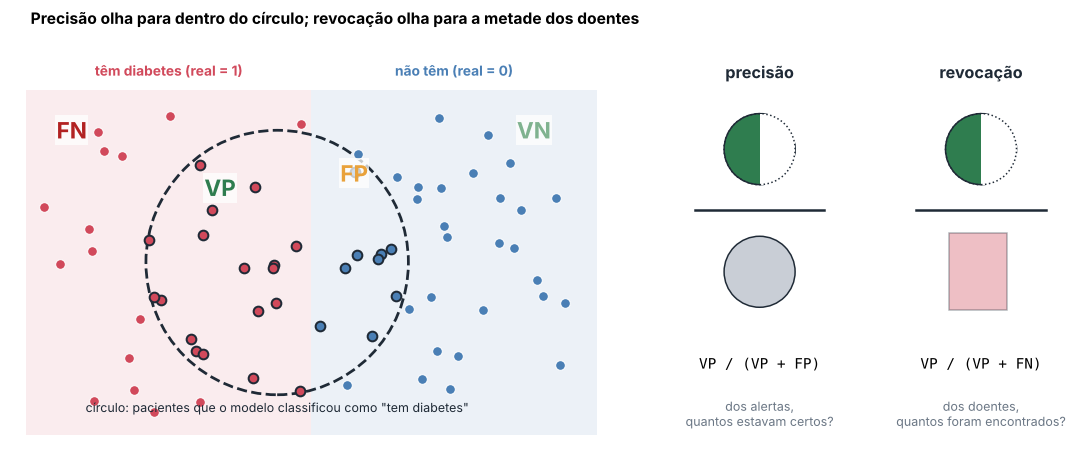

*Precisão: dos pontos dentro do círculo (alertas), quantos são vermelhos? Revocação: dos pontos vermelhos (doentes), quantos estão dentro do círculo?*

Com os números do nosso modelo, cada métrica usa uma parte diferente da matriz de confusão:

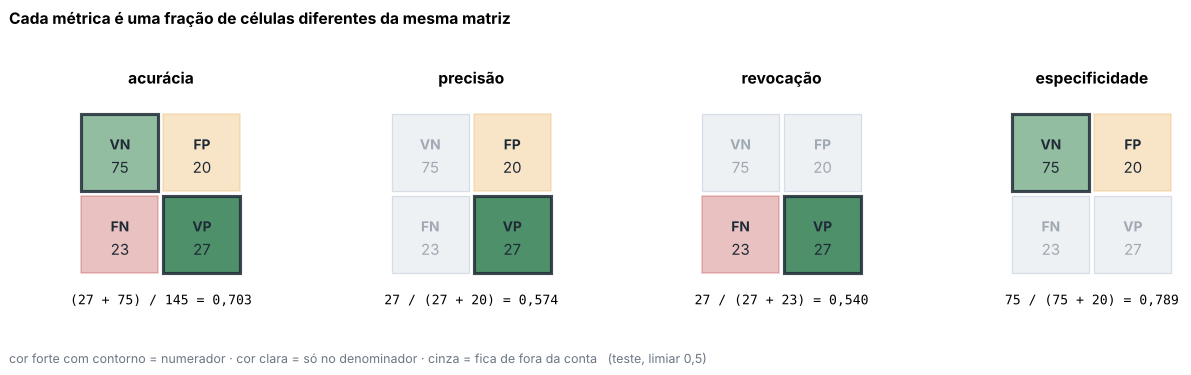

Agora calculamos as métricas na mão e conferimos com o scikit-learn:

In [9]:
acuracia       = (vp + vn) / (vp + vn + fp + fn)
precisao       = vp / (vp + fp)
revocacao      = vp / (vp + fn)
especificidade = vn / (vn + fp)
f1             = 2 * precisao * revocacao / (precisao + revocacao)

pd.DataFrame({
    'na mão':       [acuracia, precisao, revocacao, especificidade, f1],
    'scikit-learn': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                     recall_score(y_test, y_pred), recall_score(y_test, y_pred, pos_label=0),
                     f1_score(y_test, y_pred)],
}, index=['acurácia', 'precisão', 'revocação', 'especificidade', 'F1']).round(3)

,na mão,scikit-learn
acurácia,0.703,0.703
precisão,0.574,0.574
revocação,0.540,0.540
especificidade,0.789,0.789
F1,0.557,0.557


Não existe `specificity_score` no scikit-learn: a especificidade é a revocação da classe 0, por isso usamos `recall_score(..., pos_label=0)`.

### Para que serve cada métrica

A escolha da métrica vem do problema, e não do modelo. A pergunta-chave é: **qual erro custa mais caro, o alarme falso (FP) ou o caso perdido (FN)?**

#### Onde se usa a acurácia

- **Reconhecimento de dígitos escritos à mão:** as 10 classes têm quantidades parecidas e confundir um 3 com um 8 custa o mesmo que confundir um 1 com um 7.
- **Classificar fotos de produtos por categoria em um catálogo:** erros têm custo parecido e as categorias são equilibradas.
- **Primeira olhada em qualquer problema:** é fácil de explicar ("acerta 70 de cada 100"), mas sempre ao lado da linha de base.

> **Cuidado:** quando uma classe é rara (fraude, doença rara, defeito de fabricação) ou quando os dois erros têm custos muito diferentes.

#### Onde se usa a precisão

- **Filtro de spam:** um e-mail importante jogado no spam (FP) é pior do que um spam que chega na caixa de entrada (FN). Queremos que "isto é spam" esteja quase sempre certo.
- **Sistema de recomendação:** só cabem 10 produtos na tela; cada recomendação errada ocupa um espaço. Mede-se a precisão dos itens mostrados (precisão@10).
- **Alertas que acionam uma ação cara:** enviar um técnico para manutenção preventiva, ligar para um cliente que "vai cancelar": cada alarme falso custa dinheiro e tempo.

> **Cuidado:** se o modelo emitir poucos alertas, a precisão pode ser alta e a maioria dos casos continuar sem ser detectada. Olhe a revocação junto.

#### Onde se usa a revocação (sensibilidade)

- **Triagem médica:** na triagem de diabetes ou câncer, deixar um doente sem diagnóstico (FN) é muito mais grave do que pedir um exame confirmatório a mais (FP).
- **Detecção de fraude em cartão:** cada fraude não detectada é prejuízo; um alerta falso custa uma mensagem de confirmação ao cliente.
- **Inspeção de peças críticas:** em freios ou peças de avião, uma peça com defeito que passa pela inspeção é inaceitável.

> **Cuidado:** um modelo que diz "positivo" para todos tem revocação 100%. Olhe a precisão (ou a especificidade) junto.

#### Onde se usa a especificidade

- **Exame confirmatório:** depois da triagem, o segundo exame precisa evitar que pessoas saudáveis recebam um diagnóstico errado.
- **Teste antidoping:** acusar um atleta limpo (FP) tem consequências graves; queremos que quase todos os negativos sejam reconhecidos.

> **Cuidado:** como a revocação, ela olha só para um grupo (os negativos). Use em par com a revocação.

### A acurácia engana com classes desbalanceadas

Vamos calcular as mesmas métricas para a linha de base, que responde sempre "sem diabetes":

In [10]:
y_base = base.predict(X_test)

print(f'acurácia : {accuracy_score(y_test, y_base):.3f}')
print(f'revocação: {recall_score(y_test, y_base):.3f}')
print(f'precisão : {precision_score(y_test, y_base, zero_division=0):.3f}   (nenhum alerta emitido)')
print(confusion_matrix(y_test, y_base))

acurácia : 0.655
revocação: 0.000
precisão : 0.000   (nenhum alerta emitido)
[[95  0]
 [50  0]]


A linha de base tem acurácia de 65,5% e **não detecta nenhuma paciente com diabetes**. A precisão não está definida (0/0); o argumento `zero_division=0` diz ao scikit-learn para devolver 0 nesse caso, em vez de emitir um aviso.

Quanto mais rara a classe positiva, pior fica o problema. Numa doença que atinge 1% da população, a linha de base acerta 99%:

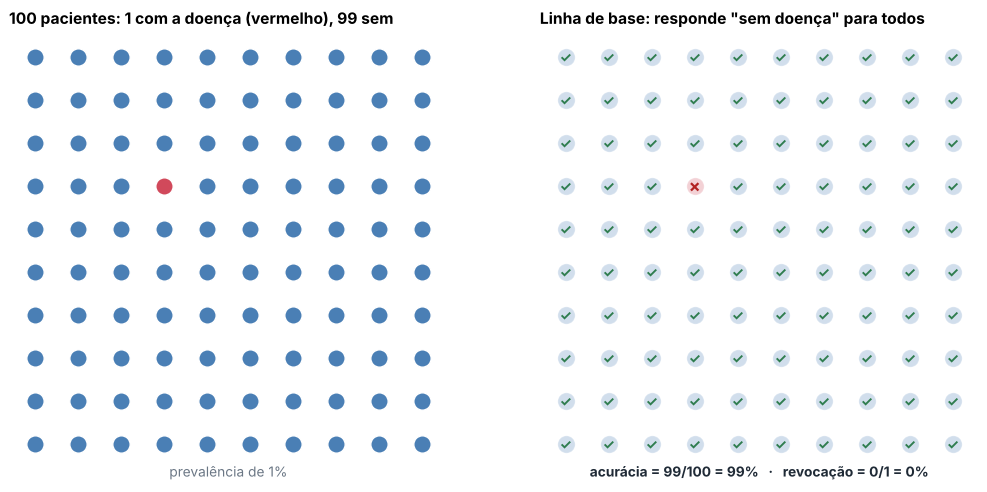

Compare com um modelo útil, que detecta 8 de cada 10 doentes e emite 20 alarmes falsos a cada 1.000 pacientes: VP = 8, FN = 2, FP = 20, VN = 970. A acurácia dele é (8 + 970) / 1000 = **97,8%**, menor que a da linha de base, embora ele encontre 80% dos doentes. Com classe rara, a acurácia ordena os modelos ao contrário do que importa.

### F1: um número só para precisão e revocação

O F1 é a **média harmônica** de precisão e revocação. Diferente da média aritmética, ela fica perto do **menor** dos dois valores, então um modelo só tem F1 alto se for bom nas duas métricas.

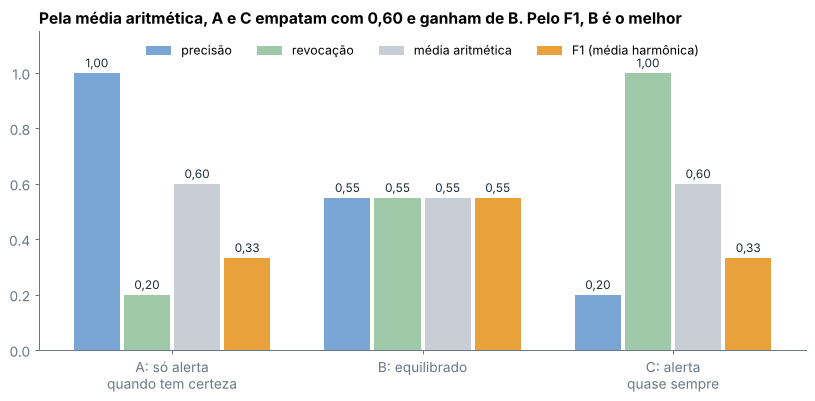

*Três modelos hipotéticos. A média aritmética recompensa quem maximiza só uma das métricas; o F1, não.*

#### Onde se usa o F1

- **Extração de nomes e datas em textos (NLP):** é preciso encontrar as entidades (revocação) sem inventar entidades que não existem (precisão).
- **Comparar modelos em bases desbalanceadas:** um número único que não é "inflado" pelos VN, como acontece com a acurácia.
- **Competições e relatórios:** muito usado para ranquear modelos quando os dois erros importam.

> **Cuidado:** quando um erro custa muito mais que o outro: o F1 dá o mesmo peso a P e R. Nesse caso, prefira olhar P e R separados, usar o custo de cada erro ou o `fbeta_score` (beta > 1 dá mais peso à revocação).

### O relatório completo

In [11]:
print(classification_report(y_test, y_pred, target_names=['sem diabetes', 'com diabetes']))

              precision    recall  f1-score   support

sem diabetes       0.77      0.79      0.78        95
com diabetes       0.57      0.54      0.56        50

    accuracy                           0.70       145
   macro avg       0.67      0.66      0.67       145
weighted avg       0.70      0.70      0.70       145



- Cada linha trata uma das classes como positiva. A revocação da linha "sem diabetes" é a especificidade calculada acima.
- `support` é o número de exemplos reais de cada classe no teste.
- `macro avg` é a média simples das duas linhas; `weighted avg` pondera pelo `support` e, por isso, fica mais perto da classe maior.

## Etapa 5 · O limiar de decisão

`predict` usa limiar 0,5, mas podemos escolher outro a partir das probabilidades de `predict_proba`. A figura mostra quantas pacientes de teste receberam cada probabilidade, separadas pela classe real. Tudo à direita da linha tracejada é classificado como "tem diabetes".

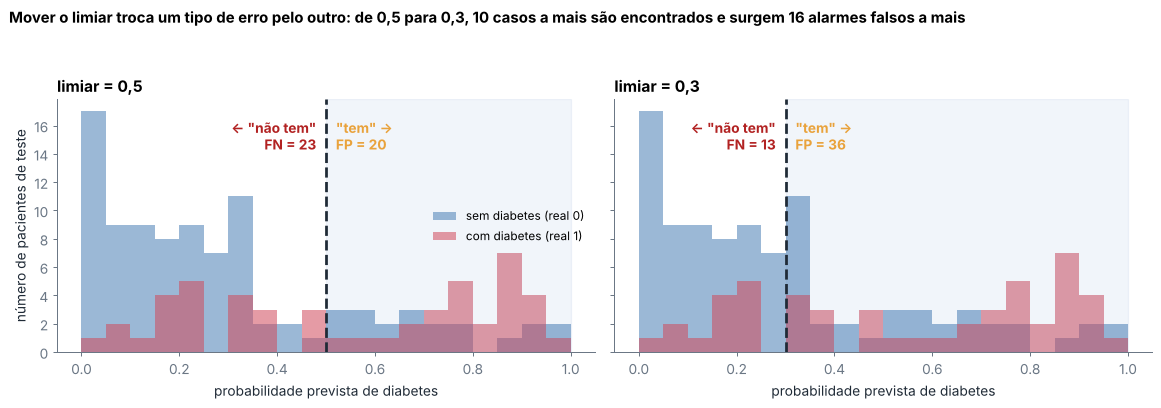

*Pacientes azuis à direita da linha são alarmes falsos (FP); pacientes vermelhas à esquerda são casos perdidos (FN). Mover a linha troca um erro pelo outro.*

Vamos montar a tabela com vários limiares:

In [12]:
modelo.predict_proba(X_test)[:, 1]

array([0.54336307, 0.66985129, 0.82710834, 0.12672682, 0.75749134,
       0.8839436 , 0.20051461, 0.18407351, 0.74468362, 0.05979788,
       0.75240322, 0.78474839, 0.31771895, 0.28580126, 0.97669752,
       0.32293198, 0.15534119, 0.15804455, 0.04606123, 0.90704434,
       0.18640376, 0.1273217 , 0.02829474, 0.86587987, 0.14641876,
       0.48555297, 0.37174445, 0.40506936, 0.21435163, 0.32014961,
       0.16213414, 0.33722285, 0.01126667, 0.2085745 , 0.54533269,
       0.04568117, 0.65245895, 0.88512455, 0.1030234 , 0.10258182,
       0.25606434, 0.1407725 , 0.1081948 , 0.16889193, 0.68000027,
       0.85475027, 0.08282794, 0.6926416 , 0.59553194, 0.92022383,
       0.64367258, 0.34659896, 0.18582366, 0.16052135, 0.26230019,
       0.05693254, 0.15309864, 0.31239028, 0.33591061, 0.6673986 ,
       0.45101894, 0.03249811, 0.49039024, 0.21845031, 0.21698127,
       0.24939282, 0.22293414, 0.17905346, 0.75480037, 0.72584859,
       0.06703447, 0.30752813, 0.0656714 , 0.74286889, 0.37008

In [13]:
p_test = modelo.predict_proba(X_test)[:, 1]      # probabilidade de diabetes

def metricas(limiar):
    previsto = (p_test >= limiar).astype(int)
    vn_, fp_, fn_, vp_ = confusion_matrix(y_test, previsto).ravel()
    return {'limiar': limiar, 'VP': vp_, 'FP': fp_, 'FN': fn_, 'VN': vn_,
            'acurácia': accuracy_score(y_test, previsto),
            'precisão': precision_score(y_test, previsto, zero_division=0),
            'revocação': recall_score(y_test, previsto),
            'F1': f1_score(y_test, previsto)}

pd.DataFrame([metricas(l) for l in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]]).round(3)

,limiar,VP,FP,FN,VN,acurácia,precisão,revocação,F1
0,0.2,42,52,8,43,0.586,0.447,0.84,0.583
1,0.3,37,36,13,59,0.662,0.507,0.74,0.602
2,0.4,30,23,20,72,0.703,0.566,0.60,0.583
3,0.5,27,20,23,75,0.703,0.574,0.54,0.557
4,0.6,25,14,25,81,0.731,0.641,0.50,0.562
5,0.7,22,9,28,86,0.745,0.710,0.44,0.543


Baixar o limiar de 0,5 para 0,3 aumenta a revocação de 0,54 para 0,74 (10 casos a mais detectados) e reduz a precisão de 0,574 para 0,507 (16 alarmes falsos a mais). A acurácia varia pouco e não mostra essa troca.

### As métricas para todos os limiares

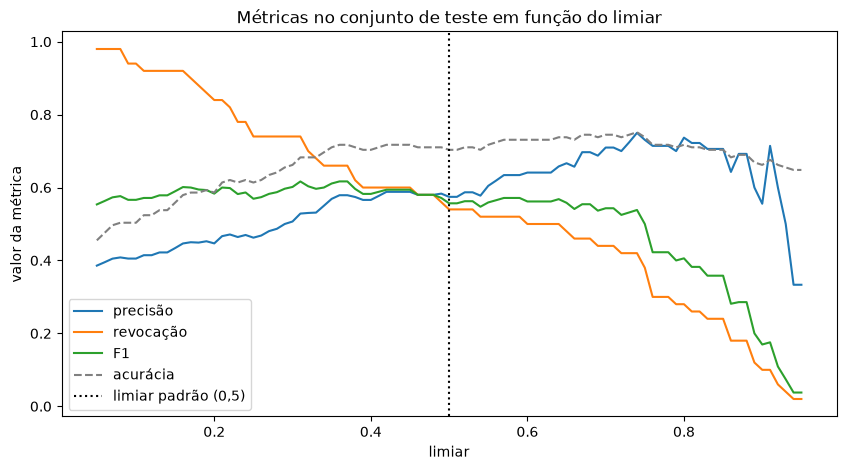

In [14]:
limiares = np.arange(0.05, 0.96, 0.01)
tabela = pd.DataFrame([metricas(l) for l in limiares])

plt.figure(figsize=(10, 5))
plt.plot(tabela['limiar'], tabela['precisão'], label='precisão')
plt.plot(tabela['limiar'], tabela['revocação'], label='revocação')
plt.plot(tabela['limiar'], tabela['F1'], label='F1')
plt.plot(tabela['limiar'], tabela['acurácia'], label='acurácia', color='gray', linestyle='--')
plt.axvline(0.5, color='black', linestyle=':', label='limiar padrão (0,5)')
plt.xlabel('limiar'); plt.ylabel('valor da métrica'); plt.legend()
plt.title('Métricas no conjunto de teste em função do limiar')
plt.show()

**Para discutir:** em uma triagem, o FN (diabetes não detectada) costuma ser mais grave do que o FP (um exame confirmatório a mais). Que região do gráfico você escolheria? E se o "alerta" fosse uma cirurgia?

## Etapa 6 · Curva ROC e AUC

A curva ROC mostra, para **todos** os limiares, a taxa de verdadeiros positivos (TVP = revocação) contra a taxa de falsos positivos (TFP = FP / (FP + VN) = 1 − especificidade).

Para construí-la, imagine o limiar descendo de 1 até 0. Cada paciente com diabetes que passa a ser detectada faz a curva **subir**; cada paciente sem diabetes que vira alarme falso faz a curva **andar para a direita**. Um bom modelo encontra muitos doentes antes de gerar alarmes falsos, então a curva sobe rápido perto do eixo esquerdo.

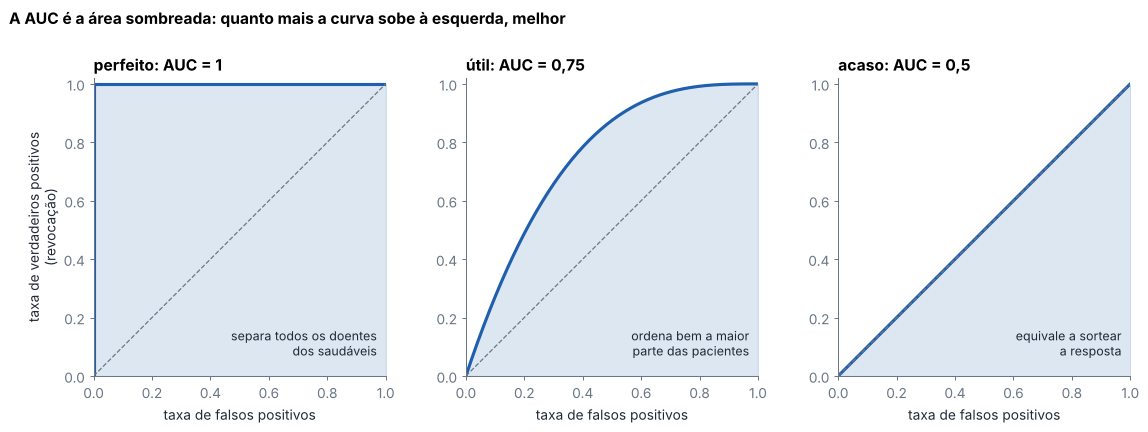

*Três curvas ROC de referência. Uma AUC abaixo de 0,5 indicaria um modelo pior que o acaso, geralmente sinal de algum erro, como classes trocadas.*

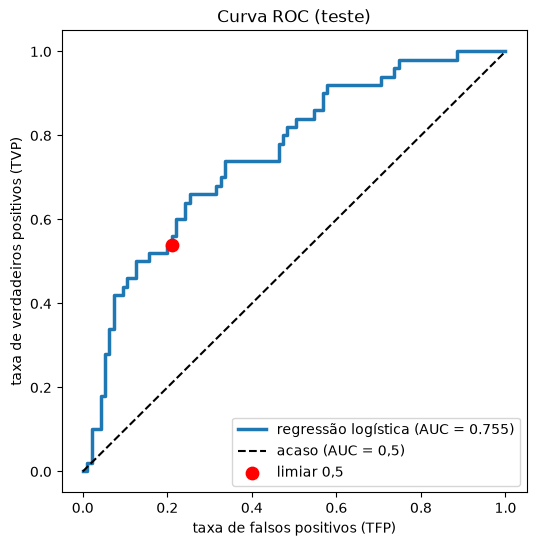

In [15]:
tfp, tvp, lim_roc = roc_curve(y_test, p_test)
auc = roc_auc_score(y_test, p_test)

# ponto correspondente ao limiar 0,5
m05 = metricas(0.5)

plt.figure(figsize=(6, 6))
plt.plot(tfp, tvp, linewidth=2.5, label=f'regressão logística (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='acaso (AUC = 0,5)')
plt.scatter(m05['FP'] / (m05['FP'] + m05['VN']), m05['revocação'], color='red', s=80, zorder=3, label='limiar 0,5')
plt.xlabel('taxa de falsos positivos (TFP)'); plt.ylabel('taxa de verdadeiros positivos (TVP)')
plt.legend(loc='lower right'); plt.title('Curva ROC (teste)')
plt.show()

### O que a AUC significa

Imagine um jogo de **duelos**. Sorteamos duas pacientes: uma **com** diabetes e uma **sem**. Mostramos as duas ao modelo e perguntamos: *"qual delas tem mais chance de ter diabetes?"*. O modelo "responde" dando uma probabilidade para cada uma, e acerta o duelo se a paciente com diabetes receber a probabilidade **maior**.

A **AUC é a porcentagem de duelos que o modelo acerta**, considerando todas as duplas possíveis.

| AUC | o que significa no jogo |
|---|---|
| 1,0 | acerta todos os duelos: todas as doentes recebem probabilidade maior que todas as saudáveis |
| 0,75 | acerta 3 de cada 4 duelos |
| 0,5 | acerta metade: é o mesmo que decidir no cara ou coroa |
| abaixo de 0,5 | erra mais do que acerta: geralmente sinal de algum erro, como classes trocadas |

Repare que, no duelo, só importa **quem ficou na frente**, e não o valor da probabilidade. Por isso a AUC **não depende do limiar**: ela mede se o modelo sabe **ordenar** as pacientes, da mais provável para a menos provável. Uma analogia é a fila de atendimento de um pronto-socorro: a AUC diz se o modelo colocou as pacientes certas no começo da fila, antes de decidirmos onde a fila será cortada.

Veja o jogo em um exemplo pequeno, com 4 pacientes com diabetes e 6 sem. São 4 × 6 = **24 duelos**. Em 21 deles, a paciente com diabetes recebeu probabilidade maior. Nos outros 3 (as setas), o modelo errou, porque uma paciente saudável ficou à frente. A AUC é 21/24 = **0,875**: o modelo acerta 87,5% dos duelos.

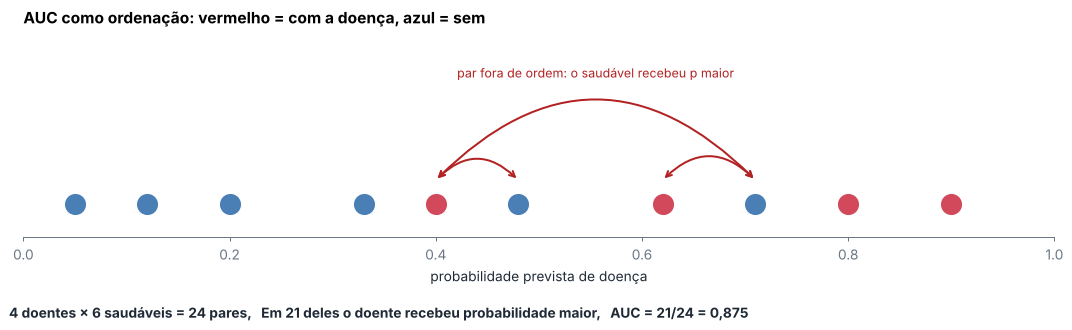

*As setas marcam os 3 pares fora de ordem. A AUC não depende de limiar: ela só pergunta se o modelo colocou os doentes à frente dos saudáveis.*


**ROC e AUC não são a mesma coisa.**

- A **curva ROC** é a **linha**. Cada ponto dela é um limiar diferente, com a sua taxa de falsos positivos (eixo x) e a sua revocação (eixo y). Ela funciona como um *cardápio*: mostra todas as trocas possíveis entre detectar mais doentes e gerar mais alarmes falsos. Escolher o limiar é escolher um ponto da curva.
- A **AUC** é a **área sob essa linha**: um único número, de 0,5 (acaso) a 1 (perfeito), que dá uma *nota* para o cardápio inteiro. Ela serve para comparar modelos, mas não escolhe nenhum limiar.

Use a AUC para comparar modelos e a curva para escolher como usar o modelo escolhido.

#### Onde se usa a AUC da ROC

- **Score de crédito:** o banco ordena os clientes por risco; o ponto de corte (quem recebe crédito) muda com a política comercial, mas a qualidade da ordenação é a mesma.
- **Priorização de atendimento:** ordenar pacientes, chamados de suporte ou leads de vendas para atender primeiro os mais prováveis.
- **Comparar modelos antes de escolher o limiar:** um modelo com AUC maior ordena melhor, qualquer que seja o limiar escolhido depois.

---
# Parte B · Regressão: vendas (Advertising)

## Etapa 7 · Treinar e prever

Mesma base e mesma separação da aula 2.

In [30]:
ads = pd.read_csv('../../data/advertising.csv')
Xa = ads[['TV', 'Radio', 'Newspaper']]
ya = ads['Sales']

Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=42)

reg = LinearRegression().fit(Xa_train, ya_train)
ya_pred = reg.predict(Xa_test)

print('Treino:', Xa_train.shape, '| Teste:', Xa_test.shape)

Treino: (160, 3) | Teste: (40, 3)


### Resíduos

O resíduo é `real − previsto`. Positivo: o modelo **subestimou**; negativo: **superestimou**.

In [17]:
residuos = ya_test - ya_pred

pd.DataFrame({'real': ya_test, 'previsto': ya_pred.round(2), 'resíduo': residuos.round(2)}).head(8)

,real,previsto,resíduo
95,16.9,17.03,-0.13
15,22.4,20.41,1.99
30,21.4,23.72,-2.32
158,7.3,9.27,-1.97
128,24.7,21.68,3.02
115,12.6,12.57,0.03
69,22.3,21.08,1.22
170,8.4,8.69,-0.29


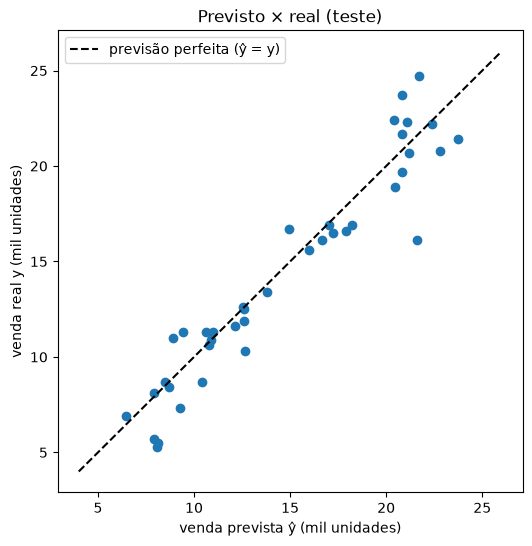

In [18]:
plt.figure(figsize=(6, 6))
plt.scatter(ya_pred, ya_test)
plt.plot([4, 26], [4, 26], 'k--', label='previsão perfeita (ŷ = y)')
plt.xlabel('venda prevista ŷ (mil unidades)'); plt.ylabel('venda real y (mil unidades)')
plt.title('Previsto × real (teste)'); plt.legend()
plt.show()

## Etapa 8 · MAE, MSE, RMSE e R²

| Métrica | Fórmula | Unidade |
|---|---|---|
| MAE | média(\|y − ŷ\|) | mil unidades |
| MSE | média((y − ŷ)²) | (mil unidades)² |
| RMSE | √MSE | mil unidades |
| R² | 1 − SQ<sub>res</sub> / SQ<sub>tot</sub> | sem unidade |

Em classificação o erro é "acertou ou errou". Em regressão, o erro é uma **distância**: o quanto a previsão ficou longe do valor real. O MAE soma os comprimentos dos resíduos; o MSE soma as **áreas dos quadrados** construídos sobre eles. Por isso um erro grande pesa muito mais no MSE.

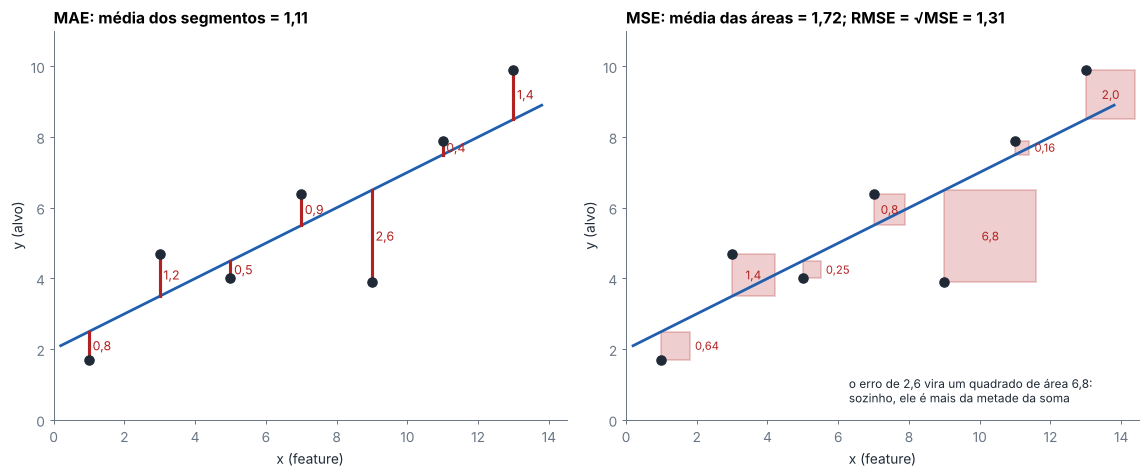

*Sete pontos de exemplo. O mesmo resíduo de 2,6 é 2,6 no MAE e 6,8 no MSE.*

O R² compara o erro do modelo com o erro de uma previsão ingênua: dizer sempre a média de y.

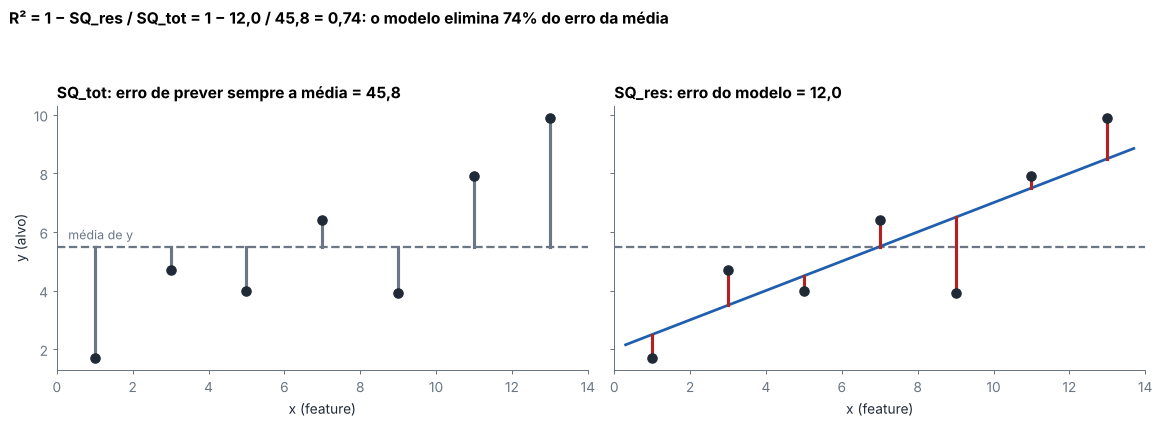

*À esquerda, os resíduos de quem prevê sempre a média; à direita, os do modelo. O R² mede quanto dessa soma de quadrados o modelo eliminou.*

Agora com os dados da Advertising:

In [32]:
mae  = np.mean(np.abs(residuos))
mse  = np.mean(residuos ** 2)
rmse = np.sqrt(mse)
sq_res = np.sum(residuos ** 2)
sq_tot = np.sum((ya_test - ya_test.mean()) ** 2)
r2   = 1 - sq_res / sq_tot

pd.DataFrame({
    'na mão':       [mae, mse, rmse, r2],
    'scikit-learn': [mean_absolute_error(ya_test, ya_pred), mean_squared_error(ya_test, ya_pred),
                     root_mean_squared_error(ya_test, ya_pred), r2_score(ya_test, ya_pred)],
}, index=['MAE', 'MSE', 'RMSE', 'R²']).round(4)

,na mão,scikit-learn
MAE,1.2748,1.2748
MSE,2.9078,2.9078
RMSE,1.7052,1.7052
R²,0.9059,0.9059


**Leitura:** em média, o modelo erra cerca de 1,3 mil unidades vendidas (MAE). O R² de 0,906 indica que o modelo elimina cerca de 91% do erro quadrático de prever sempre a média.

> `root_mean_squared_error` existe a partir do scikit-learn 1.4. Em versões anteriores, use `np.sqrt(mean_squared_error(...))`.

### A linha de base (Baseline) da regressão

In [ ]:
base_reg = DummyRegressor(strategy='mean').fit(Xa_train, ya_train) # linha de base para regressão
ya_base = base_reg.predict(Xa_test)

print(f'linha de base: MAE = {mean_absolute_error(ya_test, ya_base):.2f} | R² = {r2_score(ya_test, ya_base):.3f}')
print(f'modelo       : MAE = {mean_absolute_error(ya_test, ya_pred):.2f} | R² = {r2_score(ya_test, ya_pred):.3f}')

linha de base: MAE = 4.93 | R² = -0.032
modelo       : MAE = 1.27 | R² = 0.906


O R² da linha de base é **negativo**: ela prevê a média do treino, que é um pouco diferente da média do teste, e por isso erra mais do que a média do próprio teste. No conjunto de teste, R² < 0 significa "pior do que prever a média".

### MAE × RMSE: o efeito de um erro grande

Vamos simular um mercado em que o modelo errou por 15 mil unidades a mais e ver como cada métrica reage.

In [21]:
residuos_sim = residuos.values.copy()
i_pior = np.argmax(np.abs(residuos_sim))
residuos_sim[i_pior] = residuos_sim[i_pior] - 15        # o pior erro fica 15 mil unidades maior

for nome, r in [('original', residuos.values), ('com 1 erro grande', residuos_sim)]:
    print(f'{nome:18s} MAE = {np.mean(np.abs(r)):.2f} | RMSE = {np.sqrt(np.mean(r ** 2)):.2f}')

original           MAE = 1.27 | RMSE = 1.71
com 1 erro grande  MAE = 1.65 | RMSE = 3.56


Um único mercado muda pouco o MAE e mais que dobra o RMSE. O quadrado no RMSE dá muito peso a erros grandes; use RMSE quando eles forem especialmente prejudiciais, e MAE quando quiser o erro típico.

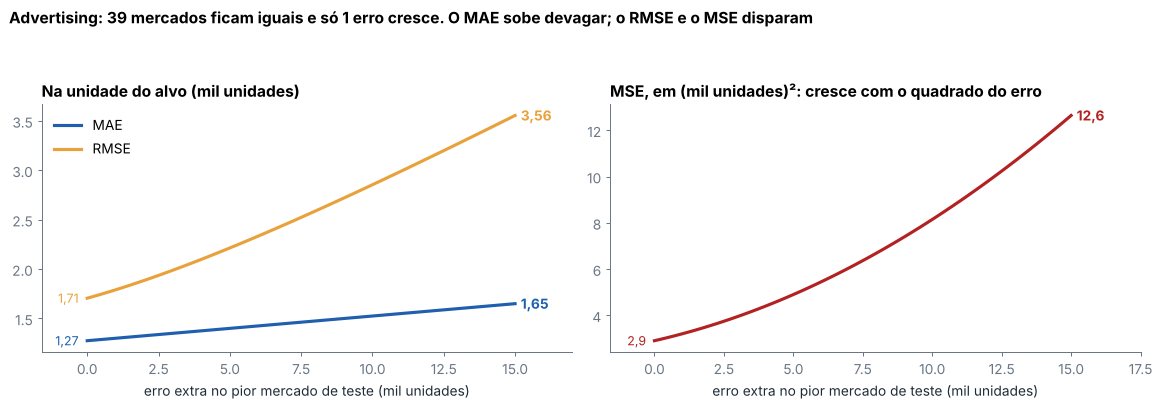

*Mesma simulação da célula anterior, agora para todos os tamanhos de erro extra, de 0 a 15 mil unidades. Repare que o MSE está em outra escala: (mil unidades)².*

O efeito também aparece ao comparar dois modelos. Imagine dois modelos que preveem a demanda de uma loja durante 10 dias e têm **exatamente o mesmo MAE**:

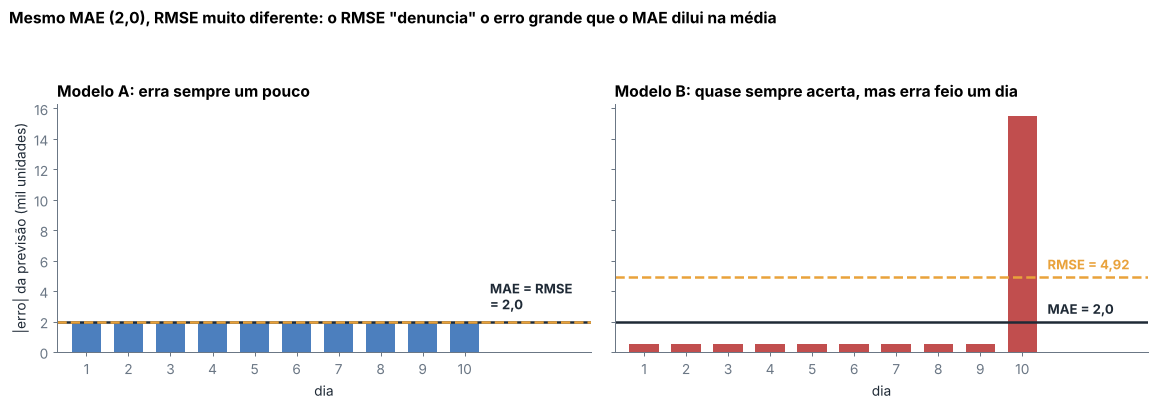

*Pelo MAE, os modelos empatam. Pelo RMSE, o modelo B é muito pior, porque o erro de 15,5 mil unidades no dia 10 pesa muito quando é elevado ao quadrado.*

Qual dos dois é melhor? **Depende do custo do erro grande.**
- Se a loja guarda o excedente no estoque e o prejuízo é proporcional ao erro, os dois modelos custam o mesmo: o **MAE** descreve bem a situação.
- Se faltar 15 mil unidades em um único dia significa clientes perdidos e prateleiras vazias, o modelo B é muito pior: o **RMSE** é a métrica que mostra isso.

Por isso, **olhar MAE e RMSE juntos** já é um diagnóstico: quando o RMSE fica muito acima do MAE, existem alguns erros bem maiores que o típico.

### Para que serve cada métrica de regressão

#### Onde se usa o MAE

- **Tempo de entrega de um aplicativo:** "em média erramos a previsão em 4 minutos" é fácil de comunicar ao cliente e à equipe.
- **Previsão de vendas diárias de uma loja:** cada unidade a mais ou a menos custa mais ou menos o mesmo.
- **Dados com valores atípicos que não interessam:** o MAE é menos afetado por alguns erros enormes, como uma venda extraordinária num feriado.

#### Onde se usa o RMSE (e o MSE)

- **Previsão de consumo de energia elétrica:** errar muito no horário de pico pode causar falta de energia; erros grandes são desproporcionalmente caros.
- **Previsão de estoque de remédios em hospitais:** faltar muito de um item é muito pior do que faltar pouco.
- **Treinar a regressão linear:** o MSE é a função de custo que a regressão linear minimiza (aula 2); o RMSE volta para a unidade do alvo.

> **Cuidado:** RMSE e MAE dependem da escala do alvo: um RMSE de 1,7 é ótimo para vendas em mil unidades e péssimo para notas de 0 a 10. Compare sempre com a escala do alvo e com a linha de base.

#### Onde se usa o R²

- **Pesquisa e relatórios científicos:** "o modelo explica 90% da variação das vendas" é a forma usual de reportar regressões.
- **Comparar o mesmo problema com features diferentes:** como não tem unidade, mostra rapidamente se um conjunto de features explica mais que outro.

> **Cuidado:** o R² não diz o tamanho do erro em unidades do alvo, e um R² alto não garante que o modelo esteja livre de erros sistemáticos. Apresente sempre junto com MAE ou RMSE e o gráfico de resíduos.

### MAE, MSE (RMSE) ou R²: comparando as três

As quatro fórmulas lado a lado, com $y_i$ o valor real, $\hat{y}_i$ a previsão, $\bar{y}$ a média dos valores reais e $n$ o número de exemplos:

| Métrica | Fórmula | Em palavras |
|---|---|---|
| **MAE** | $\text{MAE} = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$ | média do **tamanho** dos erros |
| **MSE** | $\text{MSE} = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$ | média dos erros **ao quadrado** |
| **RMSE** | $\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\dfrac{1}{n}\displaystyle\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$ | raiz do MSE: volta para a unidade do alvo |
| **R²** | $R^2 = 1 - \dfrac{\displaystyle\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\displaystyle\sum_{i=1}^{n} (y_i - \bar{y})^2} = 1 - \dfrac{SQ_{res}}{SQ_{tot}}$ | 1 menos a razão entre o erro do modelo e o erro de prever sempre a média |

Repare no que muda de uma fórmula para outra:
- **MAE × MSE:** o único passo diferente é trocar o valor absoluto $\lvert y_i - \hat{y}_i \rvert$ pelo quadrado $(y_i - \hat{y}_i)^2$. Um erro de 2 vira 4; um erro de 10 vira 100. É isso que faz o MSE pesar mais os erros grandes.
- **MSE × RMSE:** a raiz quadrada só desfaz a unidade ao quadrado. Como a raiz é aplicada **depois** da média, o RMSE continua pesando mais os erros grandes.
- **R²:** o numerador é a soma dos quadrados dos resíduos, a mesma que aparece no MSE (multiplicada por $n$). O denominador é a mesma soma para a previsão "sempre a média". Por isso $R^2 = 1 - \dfrac{\text{MSE do modelo}}{\text{MSE da média}}$.

Agora, duas diferenças que costumam confundir.

#### 1. O R² depende da variação do alvo; o MAE e o RMSE, não

O R² compara o erro do modelo com o erro de prever sempre a média. Se os valores de y já são muito parecidos entre si, prever a média já é uma boa estratégia, e sobra pouco para o modelo "explicar". Na figura, os **resíduos são exatamente os mesmos** nos dois painéis:

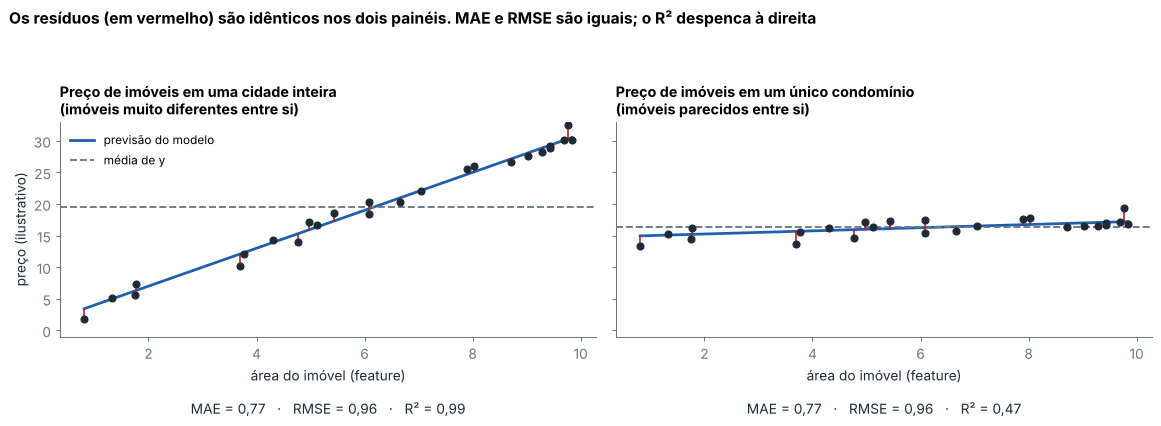

*Dados ilustrativos. O modelo da direita erra o mesmo que o da esquerda (mesmo MAE e mesmo RMSE), mas tem R² de 0,47 porque os preços dentro de um condomínio variam pouco.*

**Conclusão:** um R² baixo não quer dizer, sozinho, que o modelo erra muito; e um R² alto não quer dizer que o erro é pequeno o bastante para o uso pretendido. Por isso o R² nunca deve ser apresentado sem o MAE ou o RMSE.

#### 2. O MAE, o MSE e o RMSE dependem da unidade do alvo; o R², não

Vamos refazer as métricas da Advertising com as vendas em **unidades** em vez de **mil unidades**. O modelo e as previsões são os mesmos:

In [22]:
# mesmas previsões e mesmo modelo: só trocamos a unidade do alvo (mil unidades → unidades)
y_un, p_un = ya_test * 1000, ya_pred * 1000

pd.DataFrame({
    'alvo em mil unidades': [mean_absolute_error(ya_test, ya_pred), mean_squared_error(ya_test, ya_pred),
                             root_mean_squared_error(ya_test, ya_pred), r2_score(ya_test, ya_pred)],
    'alvo em unidades':     [mean_absolute_error(y_un, p_un), mean_squared_error(y_un, p_un),
                             root_mean_squared_error(y_un, p_un), r2_score(y_un, p_un)],
}, index=['MAE', 'MSE', 'RMSE', 'R²']).round(3)

,alvo em mil unidades,alvo em unidades
MAE,1.275,1274.826
MSE,2.908,2907756.910
RMSE,1.705,1705.215
R²,0.906,0.906


- MAE e RMSE ficam **1.000 vezes** maiores, e o MSE, **1.000.000 de vezes** maior (porque está ao quadrado). O modelo não piorou: só mudou a unidade.
- O R² continua igual, porque é uma razão entre dois erros medidos na mesma unidade.

Consequência prática: **MAE e RMSE só podem ser comparados entre modelos que preveem o mesmo alvo, na mesma unidade.** Para dizer se 1,27 é um erro grande, compare com a escala do alvo (aqui, vendas entre 1,6 e 27 mil unidades) e com a linha de base (MAE de 4,93).

#### Resumo da comparação

| | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| **Fórmula** | $\frac{1}{n}\sum \lvert y_i - \hat{y}_i \rvert$ | $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | $\sqrt{\text{MSE}}$ | $1 - \frac{SQ_{res}}{SQ_{tot}}$ |
| **O que mede** | erro típico | média dos erros ao quadrado | erro típico, com mais peso nos erros grandes | quanto do erro da média o modelo eliminou |
| **Unidade** | a do alvo | a do alvo, ao quadrado | a do alvo | nenhuma |
| **Faixa de valores** | 0 a ∞ (menor é melhor) | 0 a ∞ (menor é melhor) | 0 a ∞ (menor é melhor) | até 1 (maior é melhor); no teste pode ser negativo |
| **Sensível a erros grandes** | pouco | muito | muito | muito (usa quadrados) |
| **Fácil de explicar** | sim: "erramos 1,3 mil unidades, em média" | não: unidade ao quadrado | sim, com a ressalva dos erros grandes | sim: "explica 91% da variação" |
| **Muda com a unidade do alvo** | sim | sim | sim | não |
| **Uso principal** | comunicar o erro; erros com custo proporcional | função de custo no treino (aula 2) | erros grandes são muito caros | comparar com a média; relatórios |
| **Na Advertising (teste)** | 1,27 | 2,91 | 1,71 | 0,906 |

Para decidir:

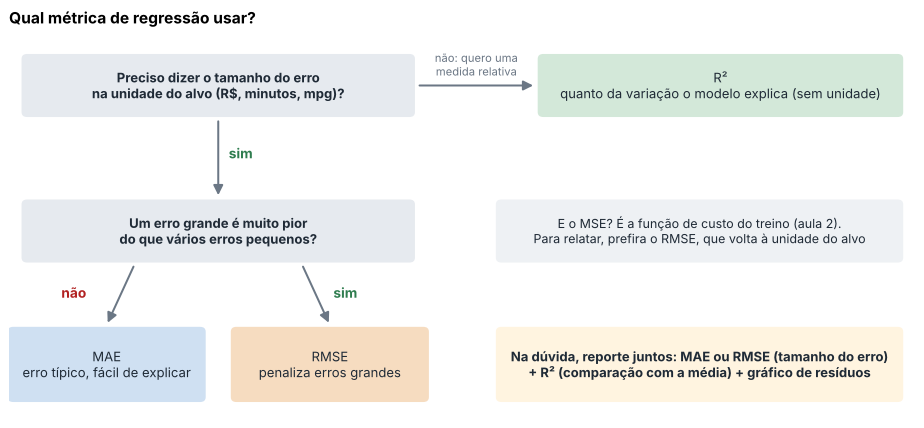

*Um roteiro simples. Na prática, a combinação mais comum é RMSE ou MAE + R² + gráfico de resíduos.*

**Na Advertising, um relatório completo diria:** "o modelo erra, em média, 1,3 mil unidades vendidas por mercado (MAE); o RMSE de 1,7 indica que não há muitos erros muito acima disso; e o R² de 0,91 mostra que ele elimina cerca de 91% do erro de prever sempre a venda média."

## Etapa 9 · O gráfico de resíduos

As métricas resumem o erro em um número; o gráfico de resíduos mostra se ele tem um padrão.

Antes de olhar os nossos dados, veja os três formatos que mais aparecem:

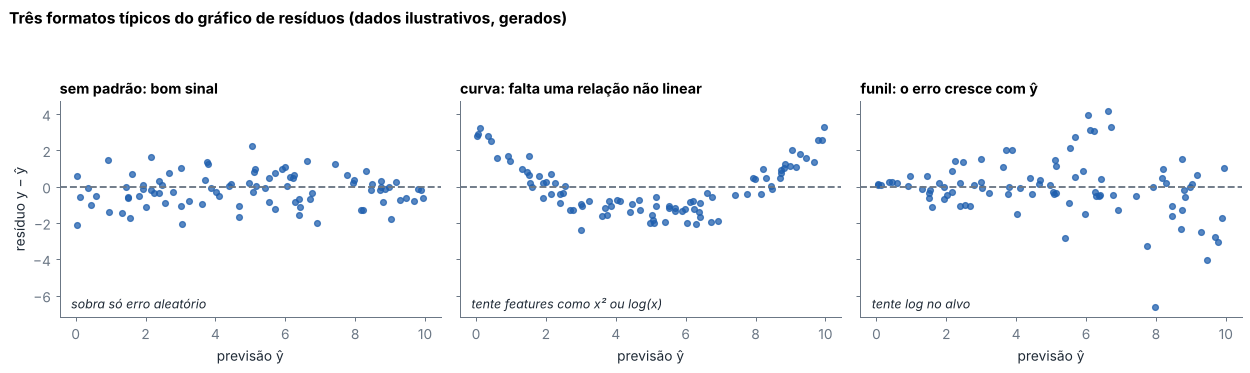

*Um modelo bom deixa só ruído. Uma curva ou um funil indicam que existe estrutura nos dados que o modelo não capturou.*

Agora, os resíduos do modelo da Advertising:

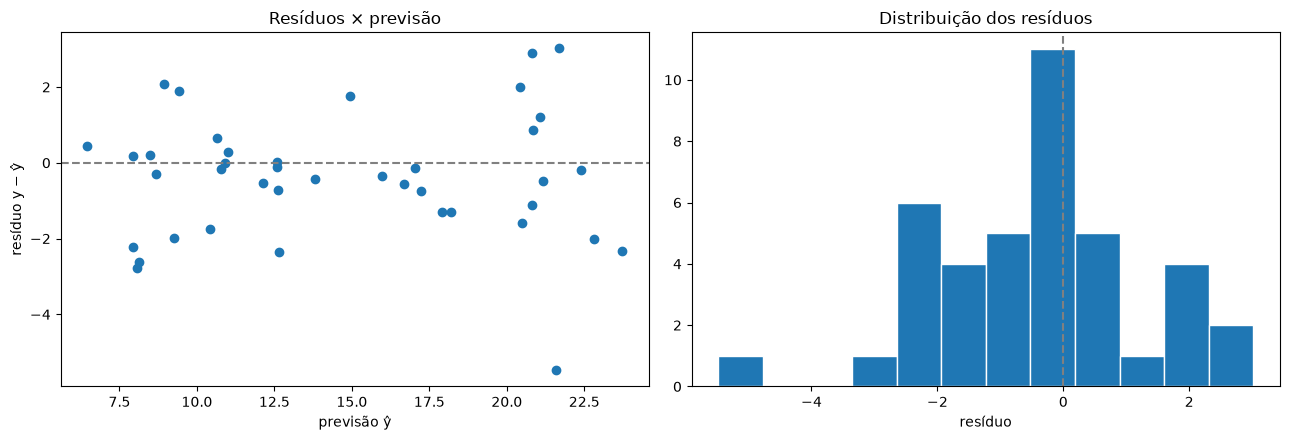

resíduos negativos: 26 de 40 | média = -0.40


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(ya_pred, residuos)
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_xlabel('previsão ŷ'); axes[0].set_ylabel('resíduo y − ŷ')
axes[0].set_title('Resíduos × previsão')

axes[1].hist(residuos, bins=12, edgecolor='white')
axes[1].axvline(0, color='gray', linestyle='--')
axes[1].set_xlabel('resíduo'); axes[1].set_title('Distribuição dos resíduos')
plt.tight_layout()
plt.show()

print(f'resíduos negativos: {(residuos < 0).sum()} de {len(residuos)} | média = {residuos.mean():.2f}')

**O que procurar:**
- **faixa sem forma em torno de 0**: o modelo captou a estrutura dos dados; sobra erro aleatório;
- **curva**: há uma relação não linear que o modelo não capturou (novas features podem ajudar);
- **funil**: o tamanho do erro cresce com a previsão.

Aqui não há uma forma clara, mas há uma leve tendência a **superestimar** (mais resíduos negativos e média abaixo de zero). Com apenas 40 pontos de teste, é difícil afirmar se esse padrão é real ou acaso.

---
# Parte C · Validação cruzada

## Etapa 10 · Uma separação só depende da sorte

Até aqui avaliamos com **uma** separação treino/teste. Com k-fold, o treino é dividido em k partes; cada parte é usada uma vez para validar um modelo treinado nas outras k − 1. O teste continua guardado.

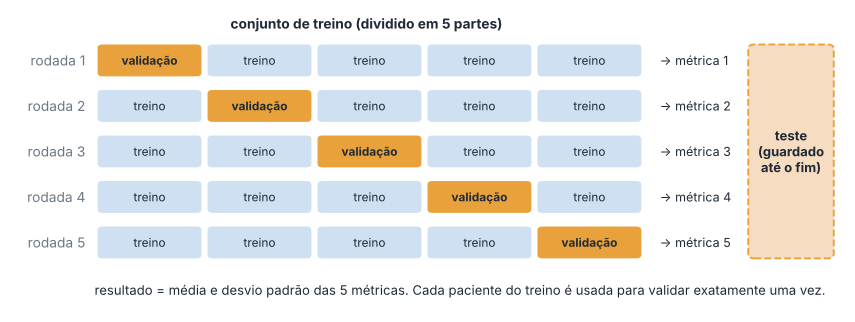

*Com k = 5, treinamos 5 modelos. Analogia: em vez de avaliar um aluno com uma única prova, aplicamos 5 provas diferentes e olhamos a média e a variação das notas.*

In [24]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res = cross_validate(LogisticRegression(max_iter=1000), X_train, y_train, cv=cv5,
                     scoring=['accuracy', 'recall', 'roc_auc'])

tabela_cv = pd.DataFrame({'acurácia': res['test_accuracy'],
                          'revocação': res['test_recall'],
                          'AUC': res['test_roc_auc']},
                         index=[f'dobra {i + 1}' for i in range(5)])
tabela_cv.loc['média'] = tabela_cv.mean()
tabela_cv.loc['desvio padrão'] = tabela_cv.iloc[:5].std(ddof=0)
tabela_cv.round(3)

,acurácia,revocação,AUC
dobra 1,0.793,0.500,0.884
dobra 2,0.759,0.500,0.837
dobra 3,0.767,0.550,0.842
dobra 4,0.741,0.675,0.838
dobra 5,0.826,0.692,0.875
média,0.777,0.583,0.855
desvio padrão,0.030,0.084,0.020


A acurácia varia de uma dobra para outra, e a média da validação cruzada fica acima do valor obtido no teste (0,703). O conjunto de teste tem só 145 pacientes e, por acaso, ficou mais difícil. A validação cruzada é a ferramenta para **comparar modelos** e **escolher hiperparâmetros**; o teste é usado uma vez, no final.

### O mesmo para a regressão

In [25]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_cv = cross_val_score(LinearRegression(), Xa_train, ya_train, cv=kf, scoring='r2')
rmse_cv = -cross_val_score(LinearRegression(), Xa_train, ya_train, cv=kf,
                           scoring='neg_root_mean_squared_error')

print('R² por dobra  :', r2_cv.round(3), f'| média {r2_cv.mean():.3f}')
print('RMSE por dobra:', rmse_cv.round(3), f'| média {rmse_cv.mean():.3f}')

R² por dobra  : [0.784 0.853 0.9   0.93  0.93 ] | média 0.879
RMSE por dobra: [1.834 2.157 1.576 1.429 1.408] | média 1.681


No scikit-learn, todo `scoring` segue a regra "maior é melhor". Por isso as métricas de erro aparecem com sinal negativo (`neg_root_mean_squared_error`) e invertemos o sinal para ler o RMSE.

### Comparando modelos com validação cruzada: Newspaper ajuda?

In [26]:
for cols in [['TV', 'Radio', 'Newspaper'], ['TV', 'Radio']]:
    r = -cross_val_score(LinearRegression(), Xa_train[cols], ya_train, cv=kf,
                         scoring='neg_root_mean_squared_error')
    print(f'{str(cols):30s} RMSE = {r.mean():.3f} ± {r.std():.3f}')

['TV', 'Radio', 'Newspaper']   RMSE = 1.681 ± 0.282
['TV', 'Radio']                RMSE = 1.658 ± 0.268


A diferença entre os dois modelos é muito menor do que a variação entre as dobras: retirar `Newspaper` não muda o erro de forma perceptível. Comparar a diferença com o desvio padrão evita escolher um modelo por um resultado que é apenas sorte.

## Etapa 11 · Validação cruzada sem vazamento: `Pipeline`

Na aula 4, o pré-processamento foi ajustado **só no treino**. Dentro da validação cruzada vale a mesma regra: em cada dobra, a padronização deve usar só os dados de treino daquela dobra. O `Pipeline` faz isso automaticamente.

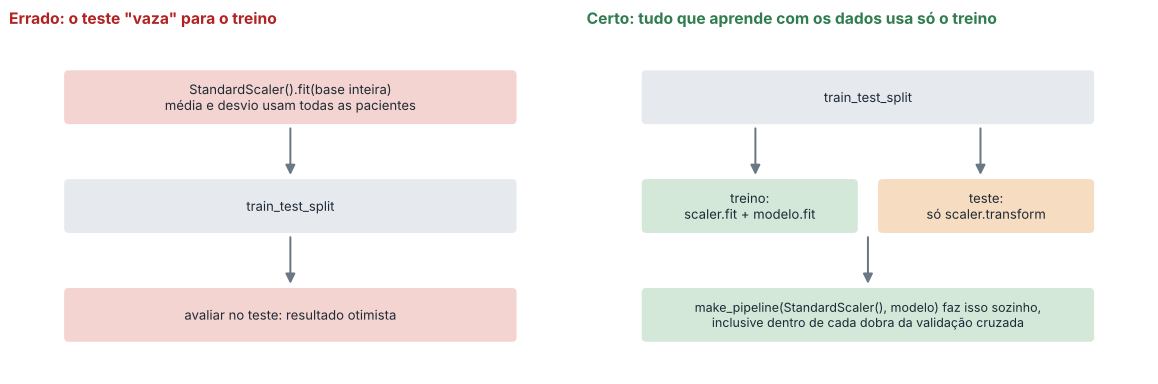

*Vazamento de dados: se a média e o desvio da padronização forem calculados com o teste, o modelo "espia" a prova antes de fazê-la.*

In [27]:
pipe = make_pipeline(StandardScaler(), LogisticRegression())

auc_cv = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring='roc_auc')
print('AUC por dobra:', auc_cv.round(3), f'| média {auc_cv.mean():.3f}')

# avaliação final, uma única vez, no teste
pipe.fit(X_train, y_train)
print(f'AUC no teste: {roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]):.3f}')

AUC por dobra: [0.887 0.834 0.843 0.833 0.875] | média 0.854
AUC no teste: 0.753


**Errado:** `StandardScaler().fit_transform(X)` na base inteira e depois `cross_val_score` ou `train_test_split`. A média e o desvio usados na padronização teriam informação das pacientes de validação e de teste.

**Certo:** passar o pipeline inteiro para `cross_val_score`; ele refaz `fit` do `StandardScaler` em cada dobra.

---
## Resumo: a receita da avaliação

```python
# 1. separar (estratificando em classificação) e guardar o teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)
# 2. comparar modelos e escolher hiperparâmetros/limiar com validação cruzada no treino
cross_val_score(make_pipeline(...), X_train, y_train, cv=5, scoring='roc_auc')
# 3. treinar o modelo escolhido no treino inteiro
modelo.fit(X_train, y_train)
# 4. avaliar uma vez no teste, sempre ao lado de uma linha de base
confusion_matrix(y_test, modelo.predict(X_test))
classification_report(y_test, modelo.predict(X_test))
roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
# regressão: mean_absolute_error, root_mean_squared_error, r2_score e o gráfico de resíduos
```

## Qual métrica usar: guia rápido

| Situação | Métrica principal | Exemplo |
|---|---|---|
| Classes equilibradas, erros com custo parecido | acurácia + matriz de confusão | dígitos escritos à mão |
| Perder um positivo é caro | revocação (limiar mais baixo) | triagem médica, fraude |
| Alarme falso é caro | precisão (limiar mais alto) | filtro de spam, recomendação |
| Não acusar negativos por engano | especificidade | exame confirmatório, antidoping |
| Os dois erros importam, base desbalanceada | F1 | extração de entidades em textos |
| Comparar modelos antes de fixar o limiar | AUC da ROC | score de crédito |
| Classe positiva muito rara | curva PR e AP | fraude, falhas de máquinas |
| Erro típico na unidade do alvo | MAE | tempo de entrega |
| Erros grandes são muito piores | RMSE | consumo de energia no pico |
| Quanto da variação o modelo explica | R² (com MAE ou RMSE) | relatórios científicos |

Em todos os casos: compare com a **linha de base**, avalie no **teste** apenas no final e use **validação cruzada** para escolher entre modelos.

## Perguntas para fechar

1. No problema de diabetes, qual métrica você reportaria para um médico responsável pela triagem? Por quê?
2. Um colega diz: "meu modelo tem 95% de acurácia". Que duas informações você pediria antes de concordar?
3. Por que não podemos escolher o limiar olhando o conjunto de teste?
4. Na Advertising, o RMSE é maior que o MAE. O que essa diferença diz sobre os erros?
5. Por que a média da validação cruzada (0,777) e a acurácia no teste (0,703) são diferentes? Qual das duas é uma estimativa mais estável?